Задача #8321 https://gitlab.sz.rshbcloud.ru/pm/p/-/issues/8321

Требуется сформировать кластеры для **авторизованных** пользователей относительно рекомендуемых им товаров

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Таблица *всех товаров:*

In [ ]:
items = pd.read_csv('item_sf.csv', dtype='str', sep=';')

In [ ]:
items.head(10)

,organization_id,item_id,section_category_nm,item_categ_lvl1_nm,item_categ_lvl2_nm,item_categ_lvl3_nm,item_categ_lvl4_nm,item_categ_lvl5_nm,item_created_dt,item_updated_dt,price_rub_amt,image_attach_cnt,item_available_ind,stock_status_ind,recomend_ind,last_categ_lvl_nm
0,9449,5535914,Каталог,Запчасти,NaN,NaN,NaN,NaN,2024-06-28,2024-08-03,1250.000000,3,1,1,1,Запчасти
1,9449,5542102,Каталог,Запчасти,NaN,NaN,NaN,NaN,2024-06-28,2025-11-19,699.000000,5,1,1,1,Запчасти
2,9449,5544613,Каталог,Запчасти,NaN,NaN,NaN,NaN,2024-06-28,2025-03-14,730.000000,3,1,1,1,Запчасти
3,9449,5560914,Каталог,Запчасти,NaN,NaN,NaN,NaN,2024-06-28,2025-11-19,712.000000,3,1,1,1,Запчасти
4,9449,5575528,Каталог,Запчасти,NaN,NaN,NaN,NaN,2024-06-28,2024-11-22,1030.000000,3,1,1,1,Запчасти
5,32027,5659545,Каталог,Запчасти,NaN,NaN,NaN,NaN,2024-07-24,2025-09-08,3331.000000,0,1,1,0,Запчасти
6,9449,5666812,Каталог,Запчасти,NaN,NaN,NaN,NaN,2024-07-24,2024-08-12,340.000000,6,1,1,1,Запчасти
7,32027,5704521,Каталог,Запчасти,NaN,NaN,NaN,NaN,2024-08-01,2024-11-26,3026.000000,1,1,0,0,Запчасти
8,9449,5582229,Каталог,Запчасти,NaN,NaN,NaN,NaN,2024-06-28,2024-09-10,4560.000000,3,1,1,1,Запчасти
9,9449,5586866,Каталог,Запчасти,NaN,NaN,NaN,NaN,2024-06-28,2025-02-27,220.000000,3,1,1,1,Запчасти


Размерность таблицы `items`

In [ ]:
items.shape

(9094876, 16)

Общая информация

In [ ]:
items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9094876 entries, 0 to 9094875
Data columns (total 16 columns):
 #   Column               Dtype 
---  ------               ----- 
 0   organization_id      object
 1   item_id              object
 2   section_category_nm  object
 3   item_categ_lvl1_nm   object
 4   item_categ_lvl2_nm   object
 5   item_categ_lvl3_nm   object
 6   item_categ_lvl4_nm   object
 7   item_categ_lvl5_nm   object
 8   item_created_dt      object
 9   item_updated_dt      object
 10  price_rub_amt        object
 11  image_attach_cnt     object
 12  item_available_ind   object
 13  stock_status_ind     object
 14  recomend_ind         object
 15  last_categ_lvl_nm    object
dtypes: object(16)
memory usage: 1.1+ GB


Пропуски в данных `items`

In [ ]:
items.isnull().sum()

,0
organization_id,0
item_id,0
section_category_nm,0
item_categ_lvl1_nm,0
item_categ_lvl2_nm,7205528
item_categ_lvl3_nm,8992893
item_categ_lvl4_nm,9052297
item_categ_lvl5_nm,9092869
item_created_dt,0
item_updated_dt,998962


Сделаем из `item_id` строки вместо чисел:

In [ ]:
items['item_id'] = items['item_id'].astype(str)

---

Выгрузка данных пользователь - рекомендации с 05.2025 - 11.2025 (6 месяцев)

In [ ]:
data = pd.read_excel('Result_75.xlsx')
data.head(10)

,domain_userid,customer_id,recomend_item_ids
0,0005fc3e-22e4-4e00-83fa-439e3462c8a5,NaN,"{613526,2463177,2225096}"
1,00061c80-a927-4861-a8af-5aaa296f8db3,NaN,"{25720455,25720462,25720510,25720481,25720461,..."
2,000ad2b7-99c6-4965-833b-6e14e9b38a59,NaN,"{2944696,2944694,2944695,2944692,2944693,37486..."
3,001224b1-0526-476a-99ba-8dc8a361522b,NaN,"{1395287,1394890,3047022,3673797,1394328,25407..."
4,0012ae31-518f-46ef-a90b-9aed8e0f47df,NaN,"{1670484,599567}"
5,001930a4-d56b-4811-a0c6-95bafb771122,NaN,"{2415567,2415578,16003,68581699,68595762,68591..."
6,001da47e-f1a8-4ec0-8183-e13778a4e849,NaN,"{68595772,68595778,68595775,68595764,68595771,..."
7,001daed6-fb9c-40ba-86a1-9c6691c1b301,NaN,"{2415567,2415578,16003,68581699,68595762,68591..."
8,0020634c-7750-4a54-84fc-111eb2484dfe,NaN,"{5686361,5686380,5686336,5686373,5686362,56863..."
9,002410cd-6bf2-4d01-af5d-0f30734e5b19,NaN,"{2298818,2207433,2207434,2207492,2207445,22074..."


Размерность таблицы `data`:

In [ ]:
data.shape

(61130, 3)

Общая информация

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61130 entries, 0 to 61129
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   domain_userid      58998 non-null  object 
 1   customer_id        2132 non-null   float64
 2   recomend_item_ids  59013 non-null  object 
dtypes: float64(1), object(2)
memory usage: 1.4+ MB


Пропуски в данных `data`:

In [ ]:
data.isnull().sum()

,0
domain_userid,2132
customer_id,58998
recomend_item_ids,2117


In [ ]:
2132+58998

61130

Есть пропуски в `recomend_item_ids`. Посмотрим, что происходит в этих случаях

In [ ]:
Nan_recomend_data = data.loc[data['recomend_item_ids'].isnull() == True]
Nan_recomend_data.head(10)

,domain_userid,customer_id,recomend_item_ids
12,00292115-cb0b-4fde-9935-876df1db636a,NaN,NaN
22,0009db93-8173-4e56-9896-120fc2e54fae,NaN,NaN
35,004280e8-dc3a-4754-a834-044c960f35ac,NaN,NaN
36,0045e037-c8ce-448d-b064-0ac4c5181525,NaN,NaN
48,00840daf-06ab-4fe0-91e8-849a2ac16347,NaN,NaN
81,00d12d0d-9fca-4377-8694-eeea3d662a60,NaN,NaN
99,00a4ccce-1cbf-4696-a1d1-1f087279097a,NaN,NaN
108,01180a0f-efca-4f84-bf10-549037c935d9,NaN,NaN
256,01ed3411-8ecf-482c-b499-d788567d2fd5,NaN,NaN
293,020656be-5159-4a46-b63b-c2b561b4ea4f,NaN,NaN


In [ ]:
recomend_data = data.loc[data['recomend_item_ids'].isnull() == False]

In [ ]:
recomend_data.isnull().sum()

,0
domain_userid,2101
customer_id,56912
recomend_item_ids,0


Будем решать задачу для авторизированных пользователей и неавторизированных *сепарированно*. В этой тетрадке решаем задачу для **авторизированных** пользователей.

In [ ]:
aut_recomend_data = recomend_data.loc[recomend_data['customer_id'].isnull() == False]

In [ ]:
aut_recomend_data = aut_recomend_data.drop('domain_userid', axis = 1)
aut_recomend_data.head(10)

,customer_id,recomend_item_ids
50602,100691.0,"{60646976,60647758,60647859,60646779,60647773,..."
50637,101459.0,"{27930655,27774956,47493058,3705358,29491382,2..."
50638,101902.0,"{608298,3671377,3223149,3671380,3014742,301456..."
50639,10717.0,"{3196040,3671427,2944480,3577975,2944479,32232..."
50646,107221.0,"{1210608,1317636,622303,606017,2924883,1661611..."
50647,111494.0,"{2459098,2459038,2459052,2458923,2458891,24590..."
50648,111726.0,"{1395417,3224439,1395430,68584464,1395388,6857..."
50689,11723.0,"{3673780,1395126,3047022,1394245,1395472,25406..."
50690,139525.0,"{25720446,25720593,25720504,25720625,25720438,..."
50781,14140.0,"{36974942,2993245,1267786,2463586,27774956,367..."


Сколько авторизированных пользователей всего?

In [ ]:
aut_recomend_data.shape

(2101, 2)

---

Считаем все `items` из `recomend_items_ids`

In [ ]:
aut_recomend_item_ids = (aut_recomend_data['recomend_item_ids']
          .str.strip('{}')  # удалить скобочки
          .str.split(',')   # разделить по запятой - получится массив
          .explode()        # для каждого item сделать отдельный столбец
          .reset_index(drop=True)  # сбросить индекс
          .to_frame(name='used_items_aut'))  # сделать dataframe pandas

aut_recomend_item_ids.head(10)

,used_items_aut
0,60646976
1,60647758
2,60647859
3,60646779
4,60647773
5,60647216
6,60646777
7,60648092
8,60647148
9,60646974


Сколько всего товаров, которые мы порекомендовали? (среди них могут быть повторы)

In [ ]:
len(aut_recomend_item_ids)

4436878

Без повторов:

In [ ]:
len(aut_recomend_item_ids['used_items_aut'].unique())

27809

Построим матрицу инцидентности `user-item` (**матрица рекомендаций**), в которой столбцами являются items, а строками - users

*Авторизованные пользователи*:

In [ ]:
aut_user_items_df = (aut_recomend_data
                 .assign(recomend_item_ids=aut_recomend_data['recomend_item_ids'].str.strip('{}').str.split(',')) # новый столбец с элементами - строками из items
                 .explode('recomend_item_ids') # для каждого item сделать отдельную строку
                 .reset_index(drop=True))

# Сделаем флаговый столбец наличия рекомендации (1 если item рекомендован для user)
aut_user_items_df['has_item'] = 1

# Сделаем Pivot таблицу, которая суммирует has item вдоль customer_id
aut_user_item_matrix = aut_user_items_df.pivot_table(
    index='customer_id',
    columns='recomend_item_ids',
    values='has_item',
    fill_value=0
).reset_index()

In [ ]:
aut_user_item_matrix.head(10)

recomend_item_ids,customer_id,1001677,10070615,10070616,10070617,10070618,10070619,10070620,10070621,10070628,...,9867563,9867565,9867568,9867570,9867583,9867599,9867601,9867605,9867614,9988
0,16.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,54.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,55.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,56.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,139.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5,404.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,499.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,593.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,1105.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,1220.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Заметим, что произошло **изменение порядка** по `customer_id`

Мы готовы приступить к кластеризации.

---

Классический способ - *Kmeans*. Итеративное повторение двух шагов:
* распределение объектов выборки по кластерам;
* пересчёт центров кластеров.

В начале работы алгоритма выбираются $K$ случайных центров в пространстве признаков. Каждый объект выборки относят к тому кластеру, к центру которого объект оказался ближе. Далее центры кластеров пересчитывают как среднее арифметическое векторов признаков всех вошедших в этот кластер объектов (то есть центр масс кластера). Как только мы обновили центры кластеров, объекты заново перераспределяются по ним, а затем можно снова уточнить положение центров. Процесс продолжается до тех пор, пока центры кластеров не перестанут меняться.

In [ ]:
from sklearn.cluster import KMeans

Нужно определить оптимальное *число кластеров*. Для этого используется классический *elbow method* (*метод локтя*):
* обучить Kmeans для различных чисел кластеров $K$;
* Для каждого $K$ вычисляется число `WCSS` (**Within-Cluster-Sum-of-Squares**):
$$WCSS = \sum_{i,k} |x_i - c_k|^2 \cdot I[a(x_i) = k]$$
-- это сумма квадратов расстояний $|x_i - c_k|^2$, где $x_i$ -- объект, а $c_k$ -- центр его кластера. Чем больше - тем менее кластеры цельны.

Эвристика: посмотреть когда `WCSS` начал стабилизироваться. Это отвечает оптимальному $K$.

---

*Авторизованные пользователи:*

In [ ]:
X_aut = aut_user_item_matrix.drop(['customer_id'], axis = 1) # матрица рекомендаций из которой выкинули id пользователей

In [ ]:
wcss = []

for k in range(1,15):
  kmeans = KMeans(n_clusters = k)
  kmeans.fit(X_aut)
  wcss.append(kmeans.inertia_)

In [ ]:
wcss

[3871419.9752499037,
 2355473.538202504,
 1527694.8213046368,
 1304026.8483929783,
 1193735.5743322796,
 1021239.4288614128,
 1085904.7088301128,
 885858.7518533162,
 660016.5925742972,
 667552.1279045315,
 630865.3772203027,
 585594.6481372154,
 558679.52458038,
 534603.7068383395]

<function matplotlib.pyplot.show(close=None, block=None)>

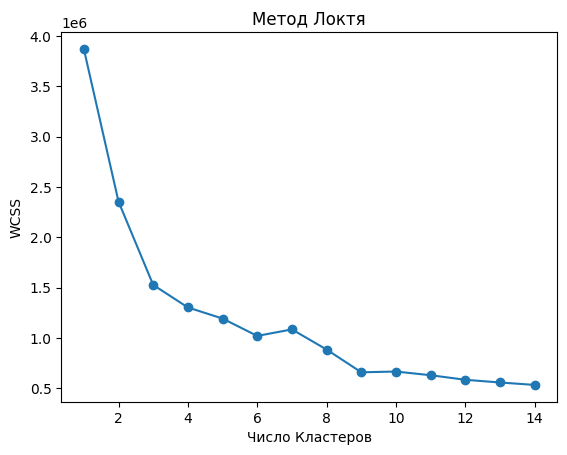

In [ ]:
plt.plot(range(1,15), wcss, marker = "o")
plt.title("Метод Локтя")
plt.xlabel("Число Кластеров")
plt.ylabel("WCSS")
plt.show

Мы видим, что оптимальное число кластеров для авторизированных пользователей равно $8$

Делаем кластеризацию авторизированных пользователей с параметром $K=8$

In [ ]:
kmeans_aut = KMeans(n_clusters = 8)
kmeans_aut.fit(X_aut)

KMeans()

In [ ]:
y_aut = kmeans_aut.predict(X_aut)

Таким образом, `y_aut` - вектор, в котором записаны нумера кластеров для каждого пользователя. Заметим, что **порядок пользователей** определяется колонкой `customer_id` из таблицы `aut_user_item_matrix`

In [ ]:
len(y_aut)

2101

---

Соберем информацию о пользователях и кластерах

1) Сформируем матрицу `cluster_customer_recomend` вида *кластер-пользователь-рекомендации:*

In [ ]:
cluster_customer_recomend = aut_recomend_data.sort_values('customer_id') # помним, что нужно упорядочить customer_id

cluster_customer_recomend['cluster'] = y_aut # прикрепляем кластер

cluster_customer_recomend = cluster_customer_recomend[['cluster','customer_id','recomend_item_ids']] # меняем порядок столбцов

cluster_customer_recomend.head(10)

,cluster,customer_id,recomend_item_ids
51013,7,16.0,"{2298818,35145761,2225075,18134295,68594848,22..."
60920,0,54.0,"{17817767,907357,1573871,2299201,2540749,13675..."
60923,1,55.0,"{59798941,9562,62676683,2944477,1343206,254061..."
57679,3,56.0,"{1407292,604465,1407287,1994492,47493058,41649..."
60224,4,139.0,"{30553332,10971736,3674088,2851723,1316836,568..."
61073,7,404.0,"{68039296,5686361,1407909,1341678,1407906,5686..."
61085,7,499.0,"{2681048,12684331,2415567,12684333,68585853,35..."
61095,7,593.0,"{966000,7718,68585845,67809410,67809416,661412..."
60185,7,1105.0,"{3196040,3577975,3223201,1296865,1296876,12968..."
52906,7,1220.0,"{1175906,2366712,68585849,60416755,14374479,13..."


2) Распарсить рекомендации

In [ ]:
# Шаг 1: на всякий случай сделаем из recomend_item_ids строки
cluster_customer_recomend['recomend_item_ids'] = cluster_customer_recomend['recomend_item_ids'].astype(str)

# Шаг 2: убираем {} и делаем split по ','
cluster_customer_recomend['recomend_item_ids'] = cluster_customer_recomend['recomend_item_ids'].str.strip('{}').str.split(',')

# Шаг 3: С помощью explode делаем новые столбцы
exploded_df = cluster_customer_recomend.explode('recomend_item_ids').reset_index(drop=True)

# Шаг 4: Подчистить пробелы, скобки и пустые пространства
exploded_df['recomend_item_ids'] = exploded_df['recomend_item_ids'].str.strip().str.replace('[', '').str.replace(']', '').str.replace("'", '').str.replace('"', '')

exploded_df.head(10)

,cluster,customer_id,recomend_item_ids
0,7,16.0,2298818
1,7,16.0,35145761
2,7,16.0,2225075
3,7,16.0,18134295
4,7,16.0,68594848
5,7,16.0,2207455
6,7,16.0,2207492
7,7,16.0,2207480
8,7,16.0,68304687
9,7,16.0,2207464


Проверка. У нас должно быть 2101 уникальных пользователей, 27809 уникальных рекомендуемых товара и 4436878 рекомендуемых товара.

In [ ]:
len(exploded_df['customer_id'].unique())

2101

In [ ]:
len(exploded_df['recomend_item_ids'].unique())

27809

In [ ]:
exploded_df.shape

(4436878, 3)

3) Сделать merge таблицы `items` с таблицей `exploded_df` вдоль товаров. Учесть, что не все рекомендуемые товары из `recomend_item_ids` существуют в `item_id`, поскольку могли быть позже удалены (не актуальны)

In [ ]:
# сделаем merge вдоль recomend_item_ids
merged_df = exploded_df.merge(
    items,
    left_on='recomend_item_ids',
    right_on='item_id',
    how='left'
)

Проверим. У `merged_df` должно быть столько же строк сколько у `exploded_df`

In [ ]:
merged_df.shape

(4436878, 19)

Посмотрим сколько пропусков образовалось

In [ ]:
merged_df.isnull().sum()

,0
cluster,0
customer_id,0
recomend_item_ids,0
organization_id,6683
item_id,6683
section_category_nm,6683
item_categ_lvl1_nm,6683
item_categ_lvl2_nm,44715
item_categ_lvl3_nm,637855
item_categ_lvl4_nm,2899094


4) Сгруппировать по нужным столбцам и сделать сводку по количеству пользователей и количеству (различных) товаров

In [ ]:
merged_df.columns

Index(['cluster', 'customer_id', 'recomend_item_ids', 'organization_id',
       'item_id', 'section_category_nm', 'item_categ_lvl1_nm',
       'item_categ_lvl2_nm', 'item_categ_lvl3_nm', 'item_categ_lvl4_nm',
       'item_categ_lvl5_nm', 'item_created_dt', 'item_updated_dt',
       'price_rub_amt', 'image_attach_cnt', 'item_available_ind',
       'stock_status_ind', 'recomend_ind', 'last_categ_lvl_nm'],
      dtype='object')

Выделяем нужные столбцы в сырой матрице `wet_info`

In [ ]:
wet_info = merged_df[['cluster', 'customer_id', 'recomend_item_ids', 'organization_id',
                     'section_category_nm', 'item_categ_lvl1_nm',
       'item_categ_lvl2_nm', 'item_categ_lvl3_nm', 'item_categ_lvl4_nm',
       'item_categ_lvl5_nm', 'last_categ_lvl_nm']]

Заполним пропуски в `wet_info`

In [ ]:
wet_info_filled = wet_info.copy()
categorical_cols = ['section_category_nm', 'item_categ_lvl1_nm', 'item_categ_lvl2_nm',
                   'item_categ_lvl3_nm', 'item_categ_lvl4_nm', 'item_categ_lvl5_nm']
wet_info_filled[categorical_cols] = wet_info_filled[categorical_cols].fillna('Неизвестная категория')

Группируем и делаем сводку по `customer_id` и `nunique`

In [ ]:
clusters_aut_info = wet_info_filled.groupby([
    'cluster',
    'section_category_nm',
    'item_categ_lvl1_nm',
    'item_categ_lvl2_nm',
    'item_categ_lvl3_nm',
    'item_categ_lvl4_nm',
    'item_categ_lvl5_nm'
]).agg(
    count_customer_id=('customer_id', 'nunique'), # здесь мы учли, что пользователей нельзя считать больше одного раза
    count_recomend_item_ids=('recomend_item_ids', 'nunique') # аналогично товары
).reset_index()

clusters_aut_info.head(10)

,cluster,section_category_nm,item_categ_lvl1_nm,item_categ_lvl2_nm,item_categ_lvl3_nm,item_categ_lvl4_nm,item_categ_lvl5_nm,count_customer_id,count_recomend_item_ids
0,0,Каталог,ГСМ,Масла,Гидравлическое масло,Неизвестная категория,Неизвестная категория,1,41
1,0,Каталог,ГСМ,Масла,Моторное масло,Неизвестная категория,Неизвестная категория,1,100
2,0,Каталог,ГСМ,Масла,Неизвестная категория,Неизвестная категория,Неизвестная категория,1,1
3,0,Каталог,ГСМ,Масла,Трансмиссионное масло,Неизвестная категория,Неизвестная категория,1,100
4,0,Каталог,ГСМ,Смазочные материалы,Смазки,Неизвестная категория,Неизвестная категория,1,100
5,0,Каталог,ГСМ,Технические жидкости,Антифриз,Неизвестная категория,Неизвестная категория,1,100
6,0,Каталог,ГСМ,Технические жидкости,Средства для очистки,Неизвестная категория,Неизвестная категория,1,100
7,0,Каталог,ГСМ,Технические жидкости,Тормозная жидкость,Неизвестная категория,Неизвестная категория,1,17
8,0,Каталог,ГСМ,Технические жидкости,Тосол,Неизвестная категория,Неизвестная категория,1,20
9,0,Каталог,ГСМ,Топливо,Бензин,Неизвестная категория,Неизвестная категория,1,20


In [ ]:
clusters_aut_info.to_excel('clusters_aut_info.xlsx', index=False)

Из последней таблицы сделаем выводы о кластерах. Чтобы сделать это, **визуализируем** данные:

1) Топ $5$ категорий в каждом кластере по *среднему потоку* пользователей

In [ ]:
def plot_top_categories_per_cluster_user(df, category_column, top_n=5):
    """
    График топ категорий для каждого кластера по среднему потоку пользователей.
    """
    clusters = sorted(df['cluster'].unique()) # наши кластеры
    n_clusters = len(clusters) # число кластеров

    # Вычисляем оптимальный размер сетки
    n_cols = min(3, n_clusters)  # Не больше 3-х колонок
    n_rows = (n_clusters + n_cols - 1) // n_cols  # сколько колонок

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))

    # Случай с одной строкой
    if n_rows == 1:
        axes = [axes] if n_cols == 1 else axes
    else:
        axes = axes.flatten()

    for i, cluster in enumerate(clusters):
        # выделим кластер с номером cluster
        cluster_data = df[df['cluster'] == cluster]

        # берем топ категорий
        top_categories = (cluster_data.groupby(category_column)['count_customer_id']
                        .mean() #взяли средний поток пользователей
                        .sort_values(ascending=False)
                        .head(top_n))

        # рисуем график
        if len(top_categories) > 0:
            axes[i].barh(range(len(top_categories)), top_categories.values)
            axes[i].set_yticks(range(len(top_categories)))
            axes[i].set_yticklabels([label[:30] + '...' if len(label) > 30 else label
                                   for label in top_categories.index], fontsize=9)
            axes[i].set_title(f'Cluster {cluster}\nTop {top_n} {category_column}')
            axes[i].set_xlabel('Mean Customer Count')
        else:
            axes[i].text(0.5, 0.5, f'Cluster {cluster}\nNo data',
                        ha='center', va='center', transform=axes[i].transAxes)
            axes[i].set_title(f'Cluster {cluster}')

    # Спрятать пустые подграфики
    for i in range(len(clusters), len(axes)):
        fig.delaxes(axes[i])

    plt.tight_layout()
    plt.show()

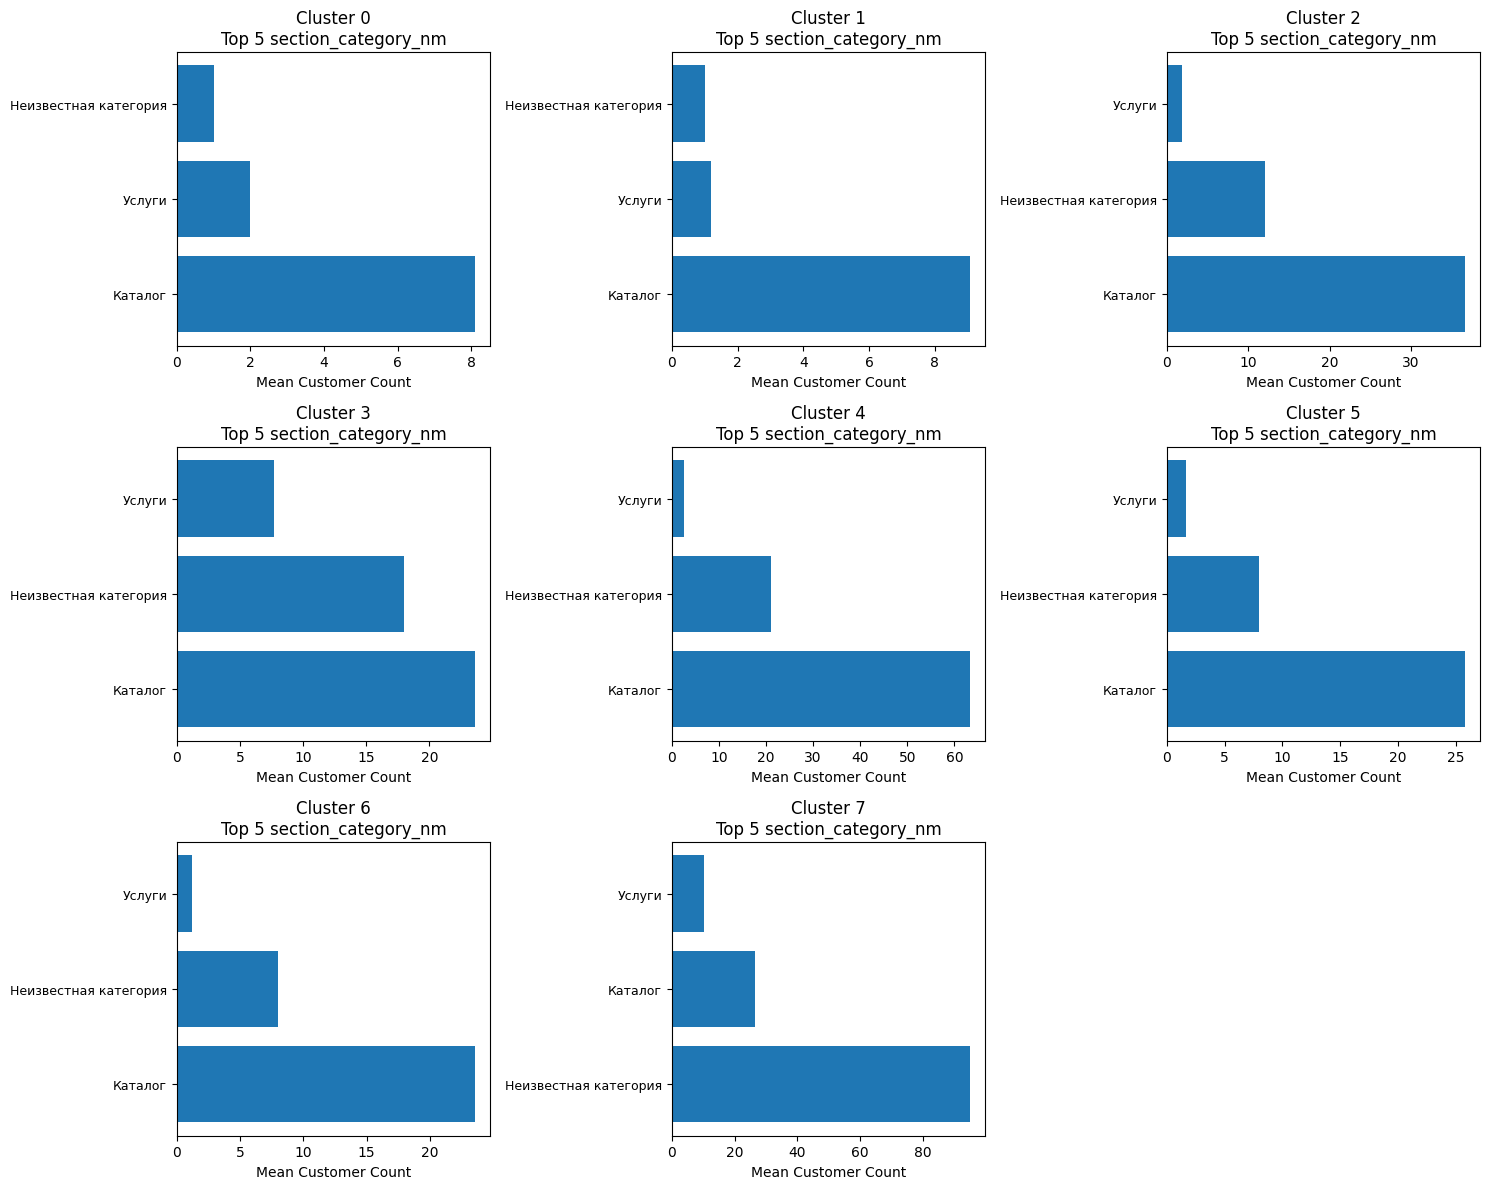

In [ ]:
plot_top_categories_per_cluster_user(clusters_aut_info, 'section_category_nm')

Уровень 1:

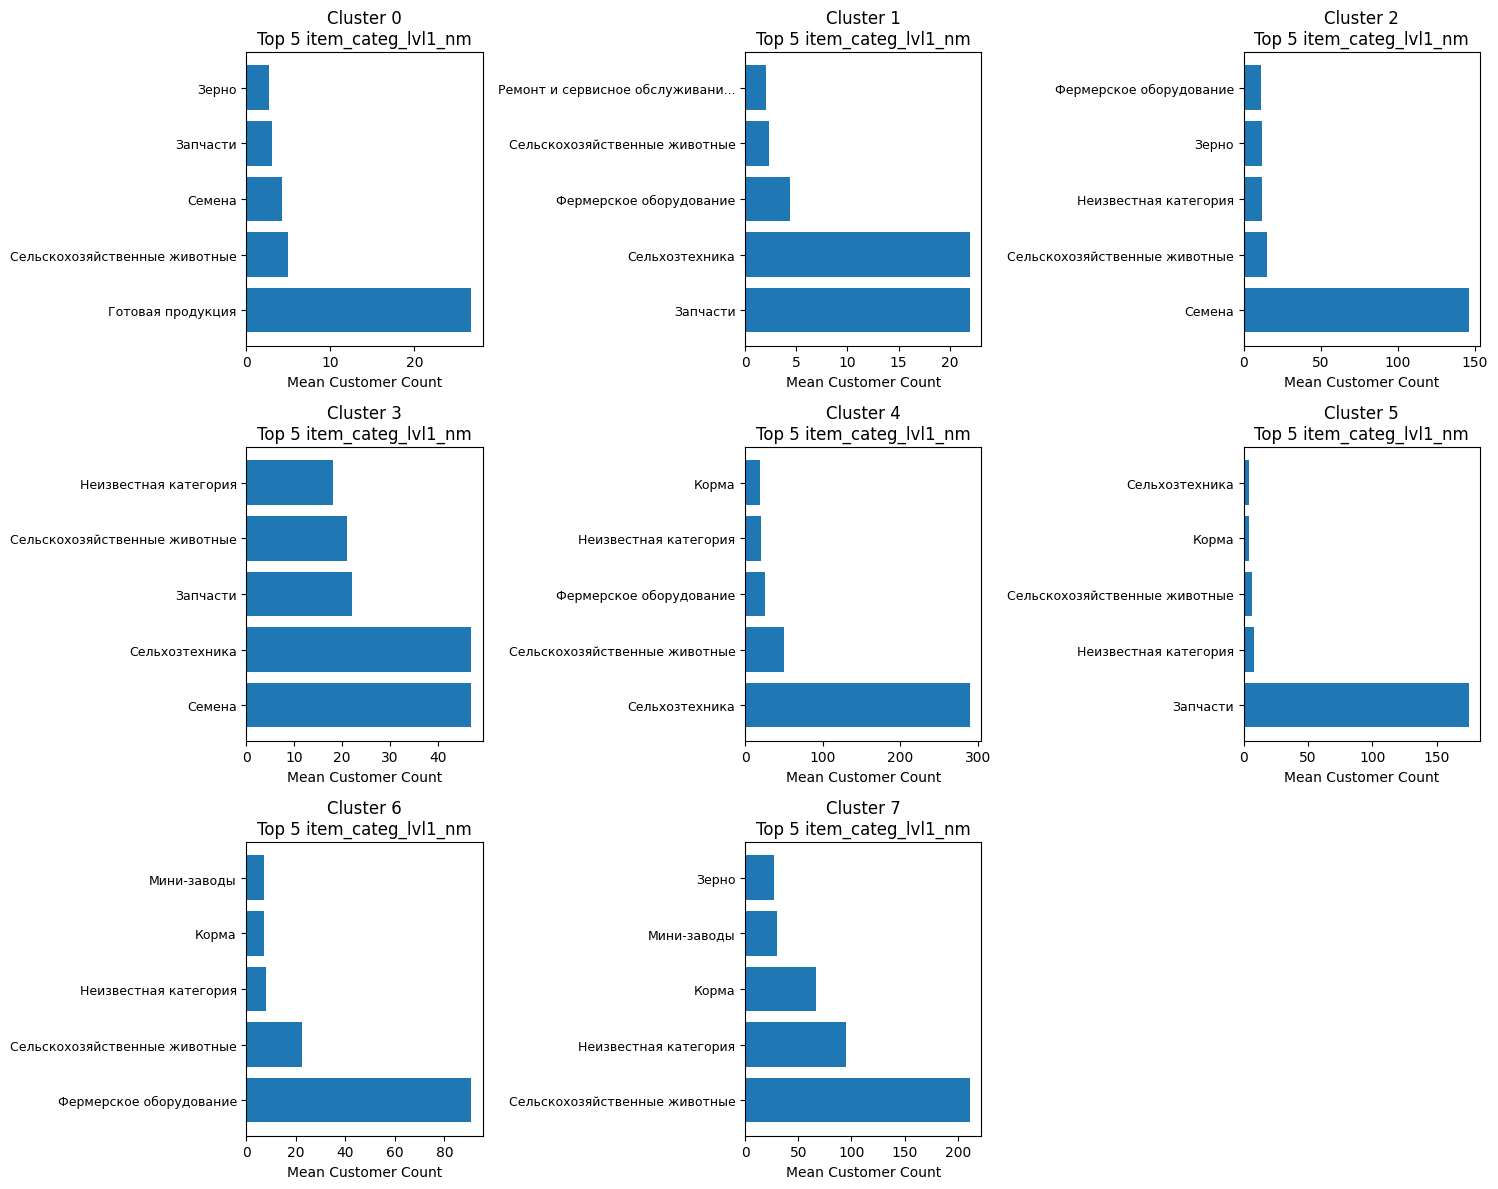

In [ ]:
plot_top_categories_per_cluster_user(clusters_aut_info, 'item_categ_lvl1_nm')

Уровень 2:

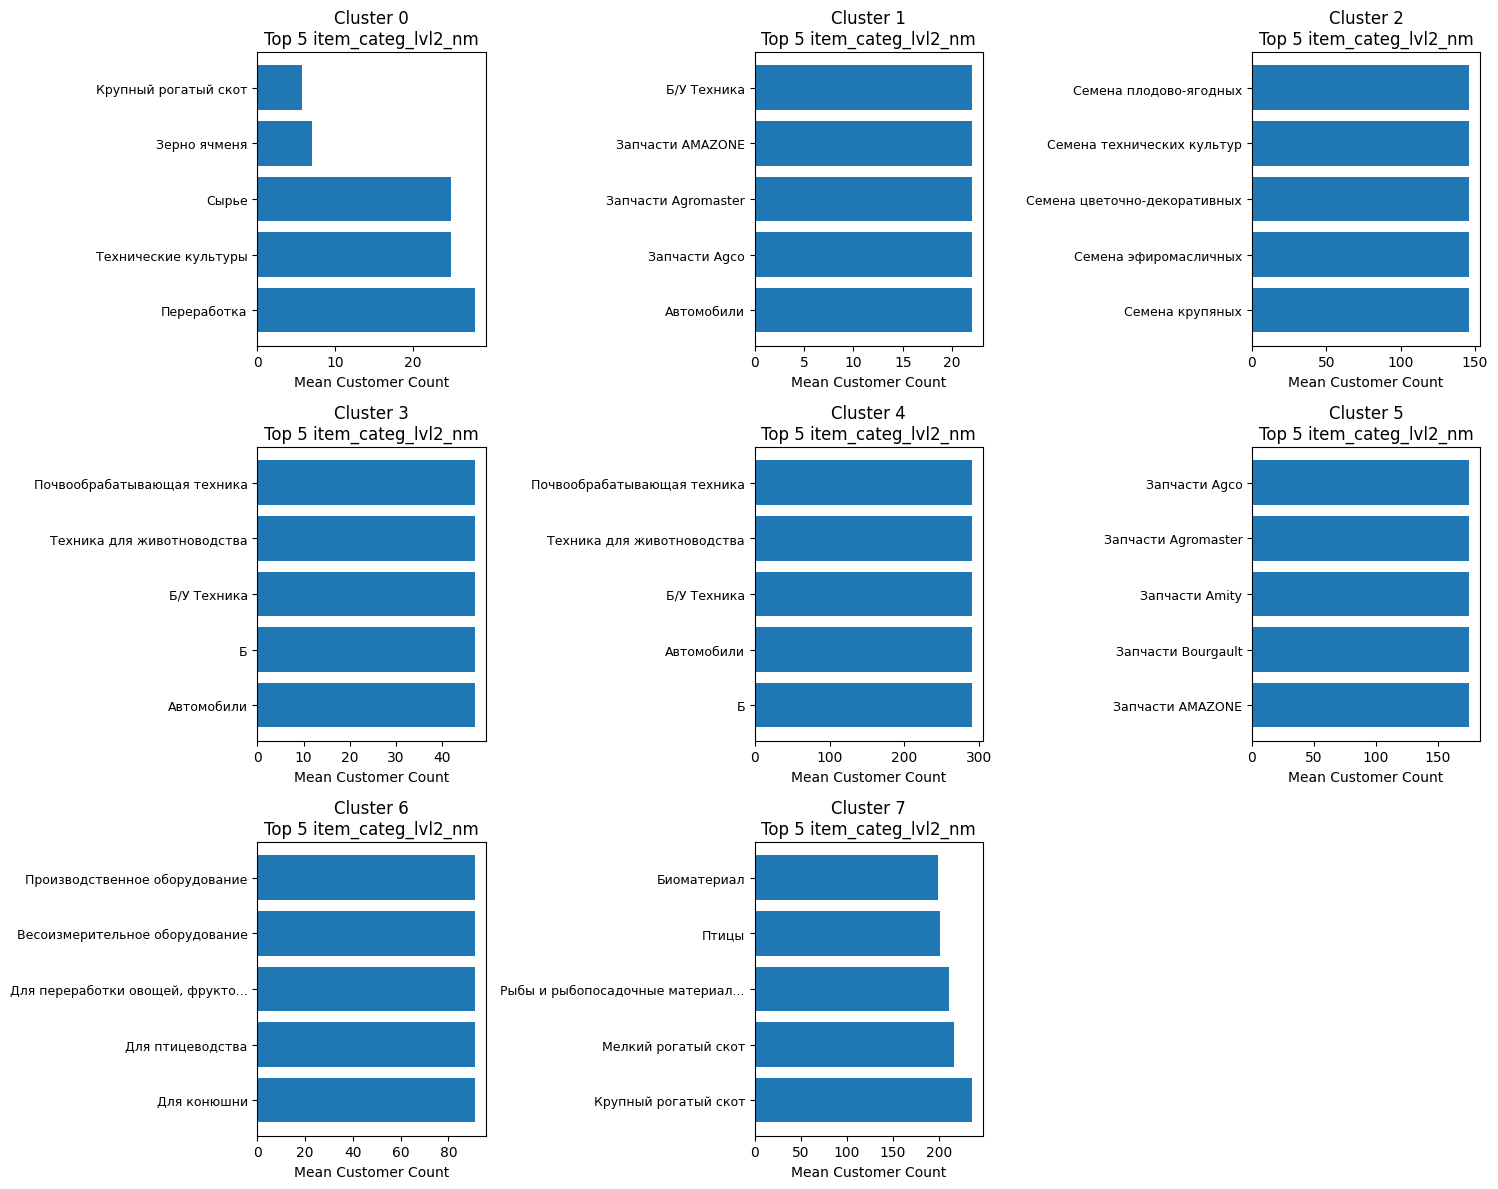

In [ ]:
plot_top_categories_per_cluster_user(clusters_aut_info, 'item_categ_lvl2_nm')

Уровень 3:

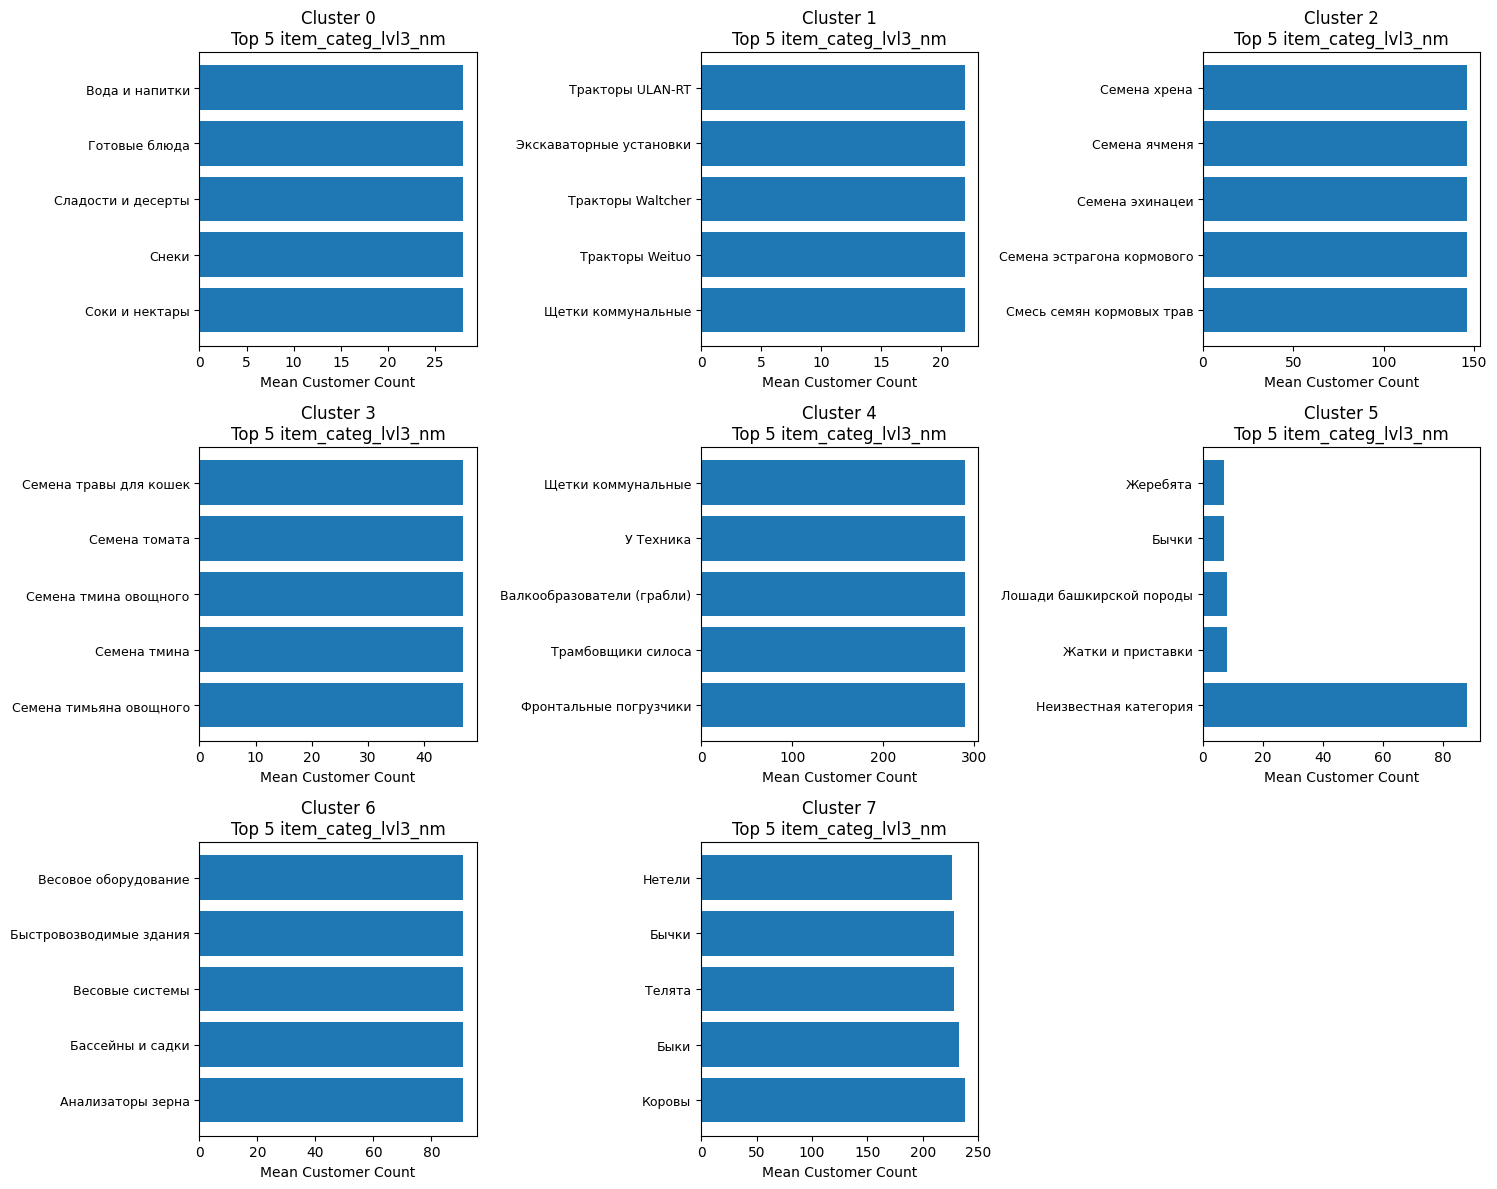

In [ ]:
plot_top_categories_per_cluster_user(clusters_aut_info, 'item_categ_lvl3_nm')

Уровень 4:

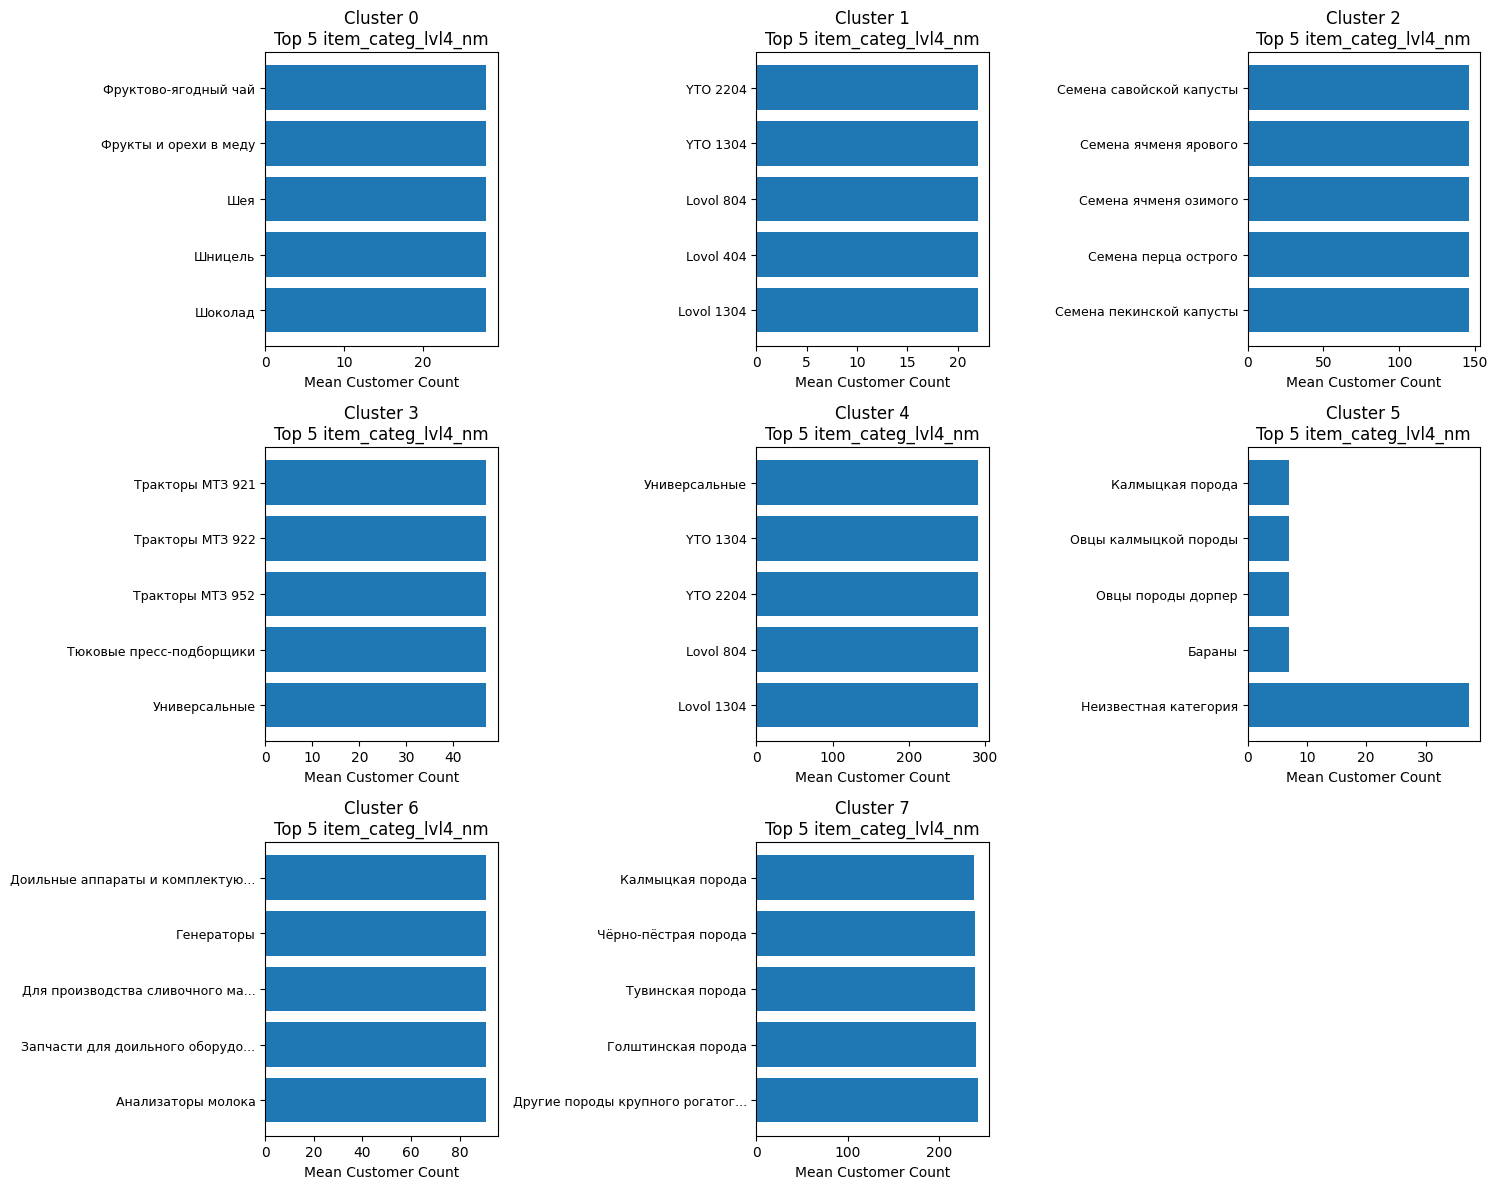

In [ ]:
plot_top_categories_per_cluster_user(clusters_aut_info, 'item_categ_lvl4_nm')

Уровень 5:

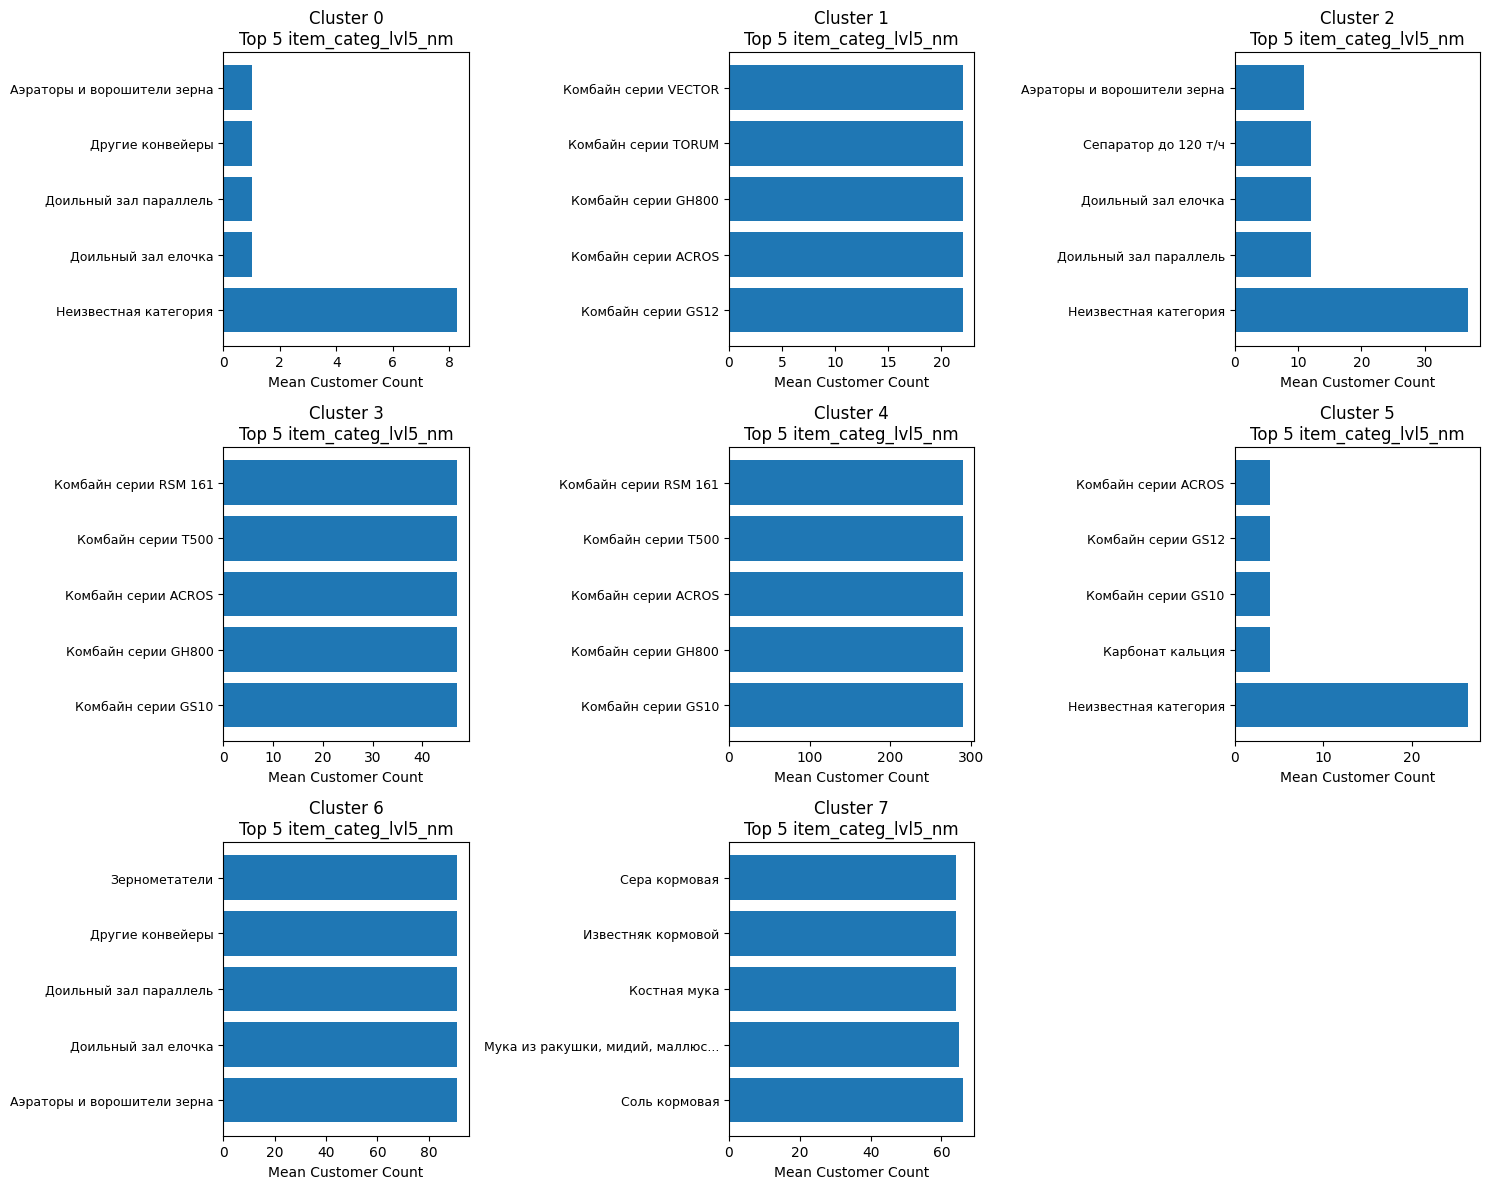

In [ ]:
plot_top_categories_per_cluster_user(clusters_aut_info, 'item_categ_lvl5_nm')

2) Топ $5$ категорий в каждом кластере по *среднему потоку* товаров

In [ ]:
def plot_top_categories_per_cluster_item(df, category_column, top_n=5):
    """
    График топ категорий для каждого кластера по среднему потоку товаров.
    """
    clusters = sorted(df['cluster'].unique()) # наши кластеры
    n_clusters = len(clusters) # число кластеров

    # Вычисляем оптимальный размер сетки
    n_cols = min(3, n_clusters)  # Не больше 3-х колонок
    n_rows = (n_clusters + n_cols - 1) // n_cols  # сколько колонок

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))

    # Случай с одной строкой
    if n_rows == 1:
        axes = [axes] if n_cols == 1 else axes
    else:
        axes = axes.flatten()

    for i, cluster in enumerate(clusters):
        # выделим кластер с номером cluster
        cluster_data = df[df['cluster'] == cluster]

        # берем топ категорий
        top_categories = (cluster_data.groupby(category_column)['count_recomend_item_ids']
                        .mean() #взяли средний поток товаров
                        .sort_values(ascending=False)
                        .head(top_n))

        # рисуем график
        if len(top_categories) > 0:
            axes[i].barh(range(len(top_categories)), top_categories.values)
            axes[i].set_yticks(range(len(top_categories)))
            axes[i].set_yticklabels([label[:30] + '...' if len(label) > 30 else label
                                   for label in top_categories.index], fontsize=9)
            axes[i].set_title(f'Cluster {cluster}\nTop {top_n} {category_column}')
            axes[i].set_xlabel('Mean Item Count')
        else:
            axes[i].text(0.5, 0.5, f'Cluster {cluster}\nNo data',
                        ha='center', va='center', transform=axes[i].transAxes)
            axes[i].set_title(f'Cluster {cluster}')

    # Спрятать пустые подграфики
    for i in range(len(clusters), len(axes)):
        fig.delaxes(axes[i])

    plt.tight_layout()
    plt.show()

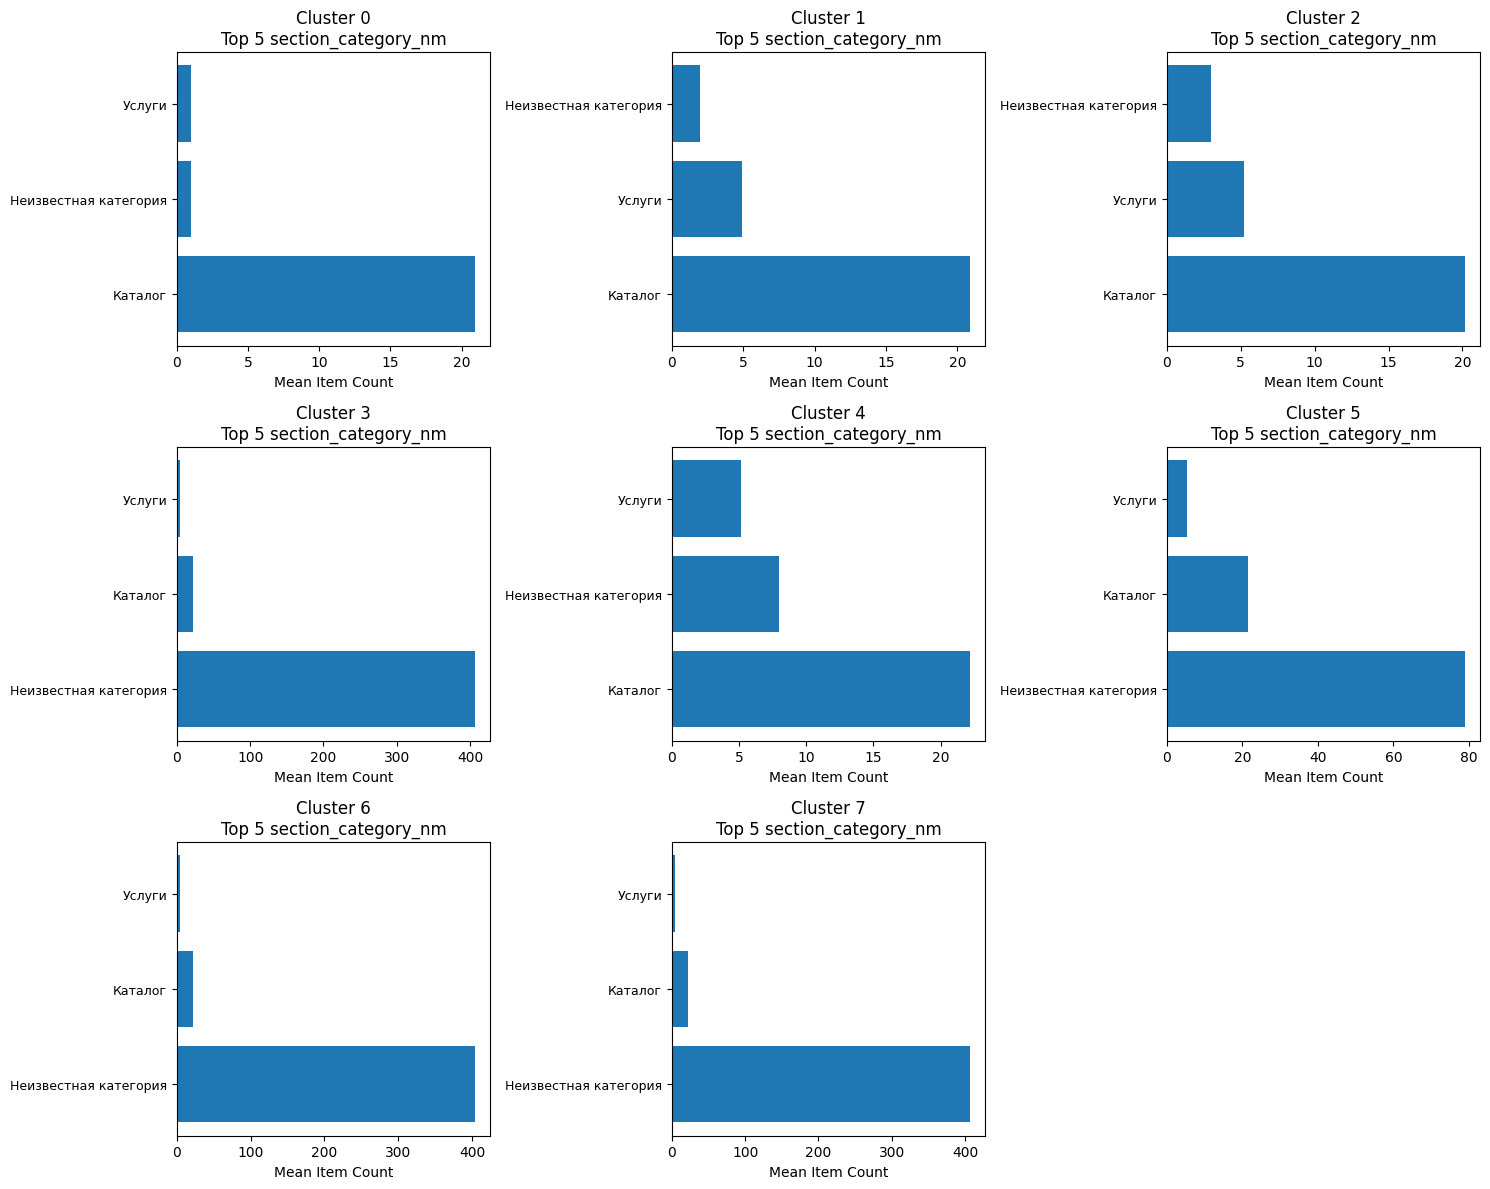

In [ ]:
plot_top_categories_per_cluster_item(clusters_aut_info, 'section_category_nm')

Уровень 1:

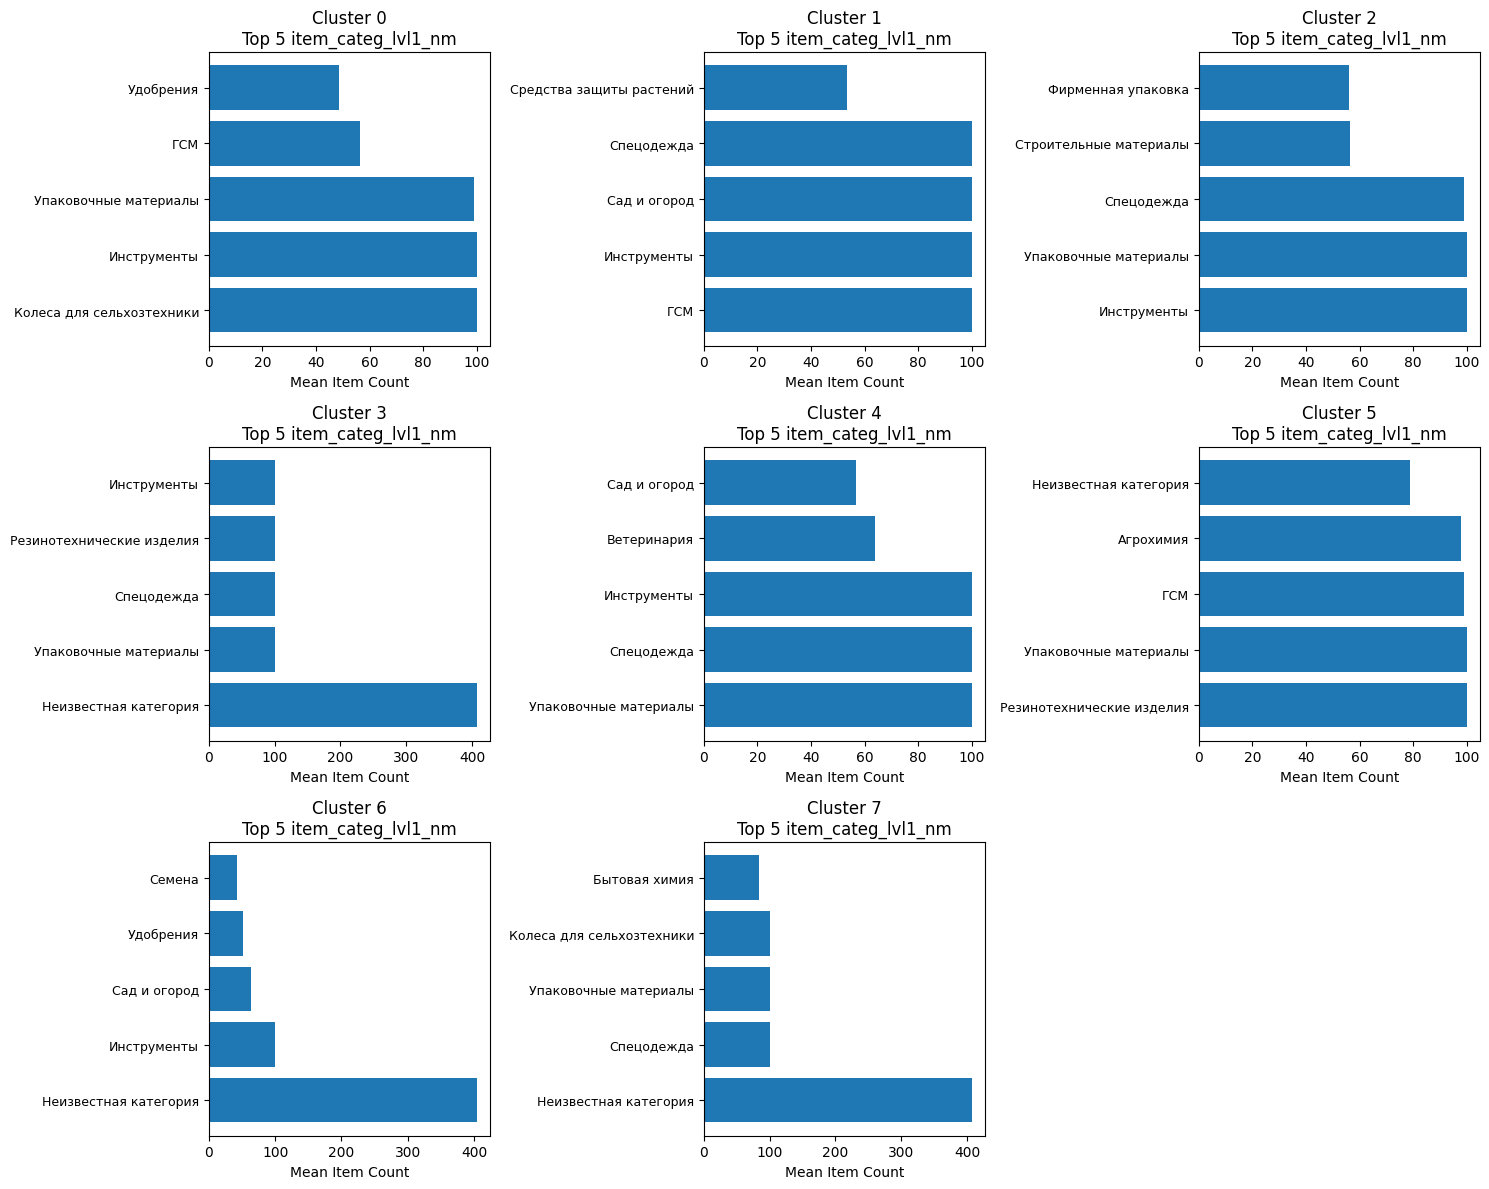

In [ ]:
plot_top_categories_per_cluster_item(clusters_aut_info, 'item_categ_lvl1_nm')

Уровень 2:

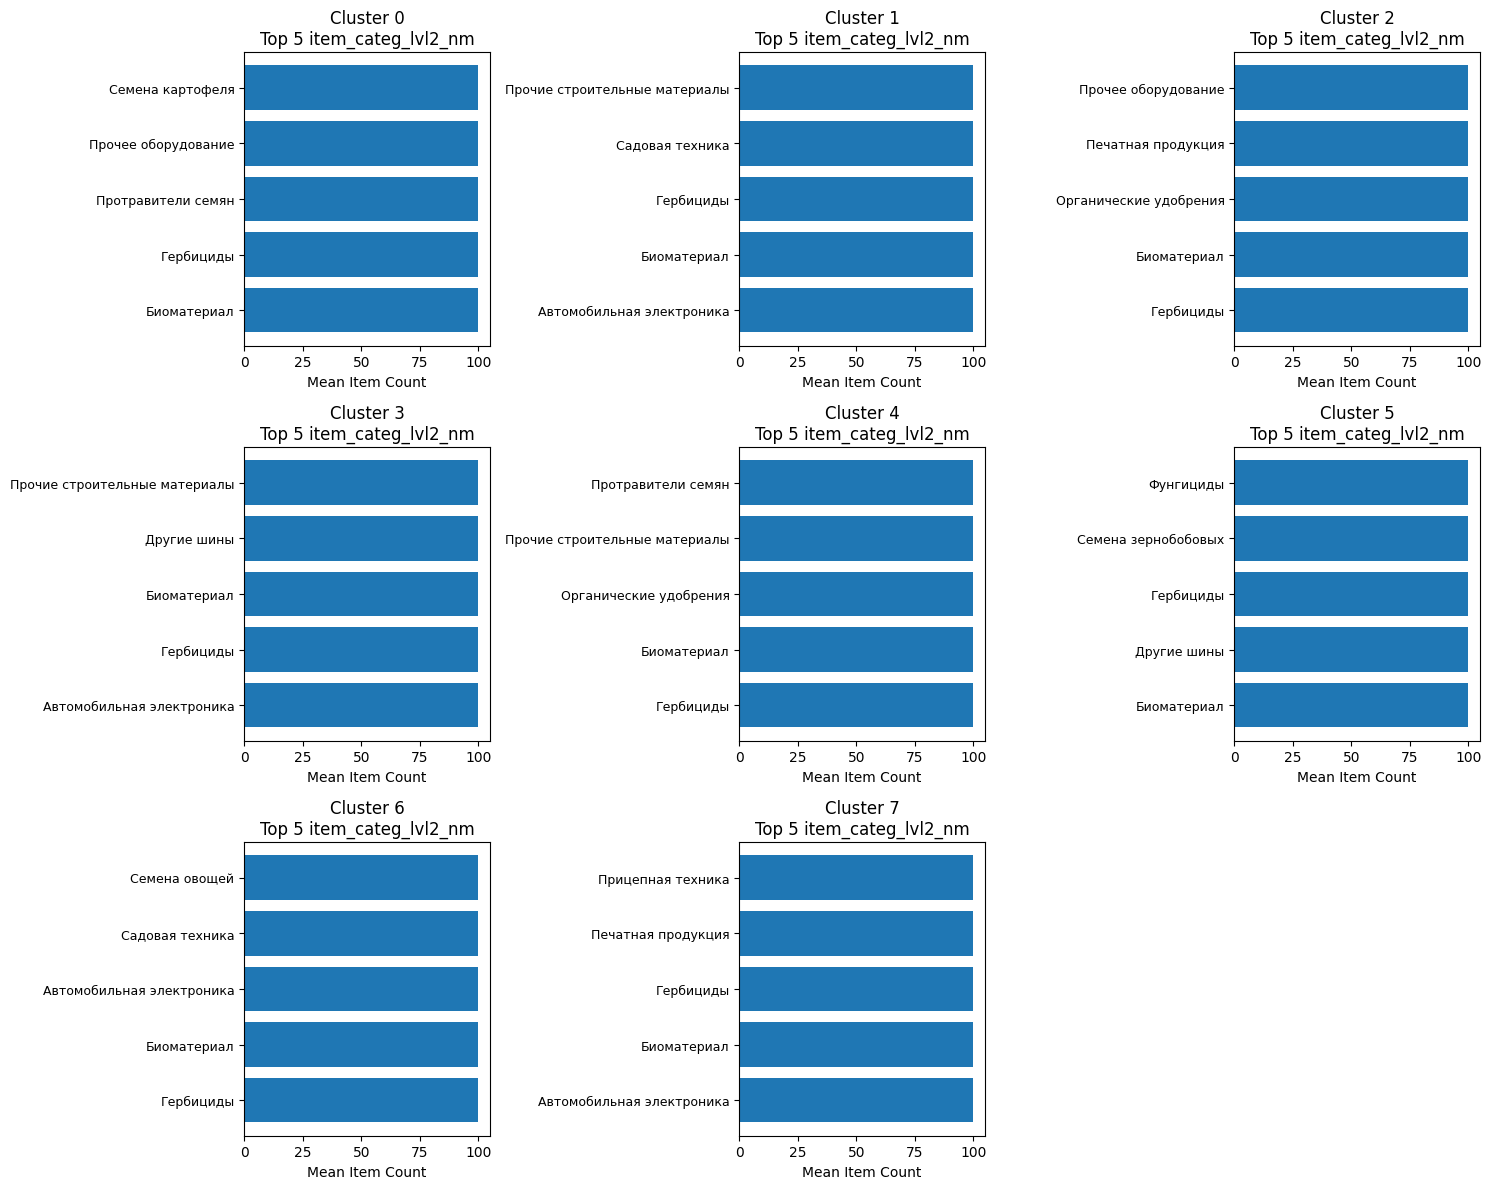

In [ ]:
plot_top_categories_per_cluster_item(clusters_aut_info, 'item_categ_lvl2_nm')

Уровень 3:

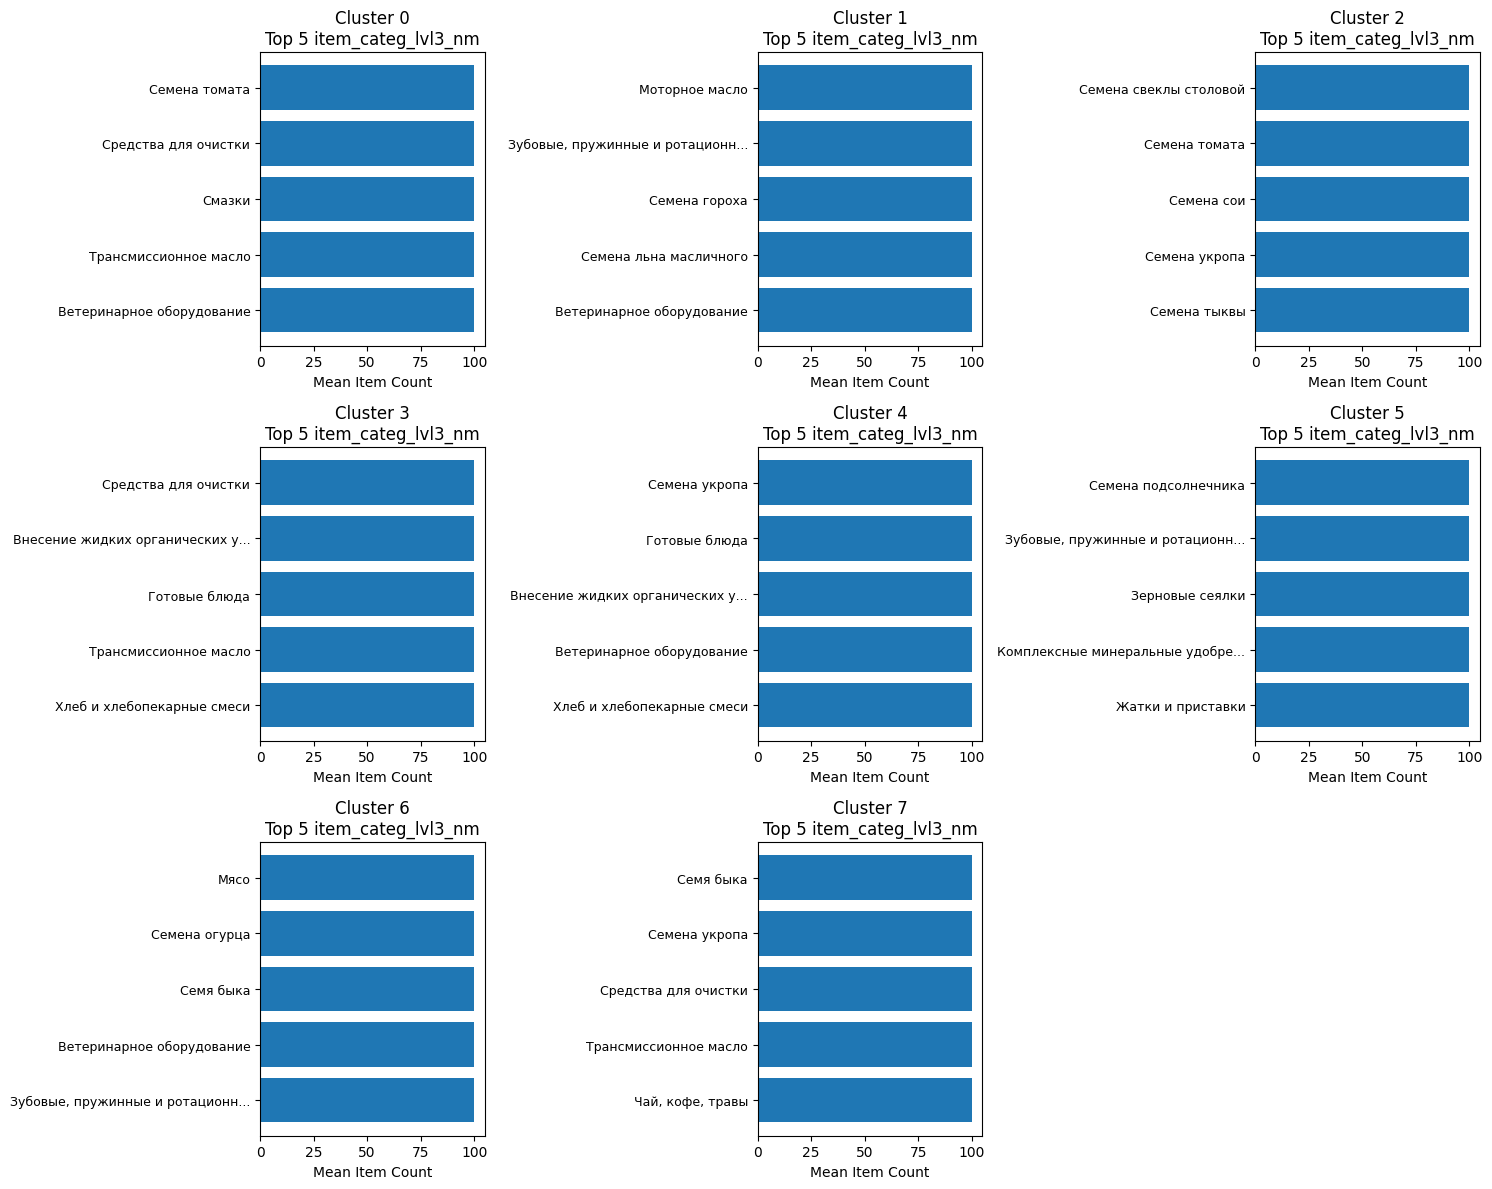

In [ ]:
plot_top_categories_per_cluster_item(clusters_aut_info, 'item_categ_lvl3_nm')

Уровень 4:

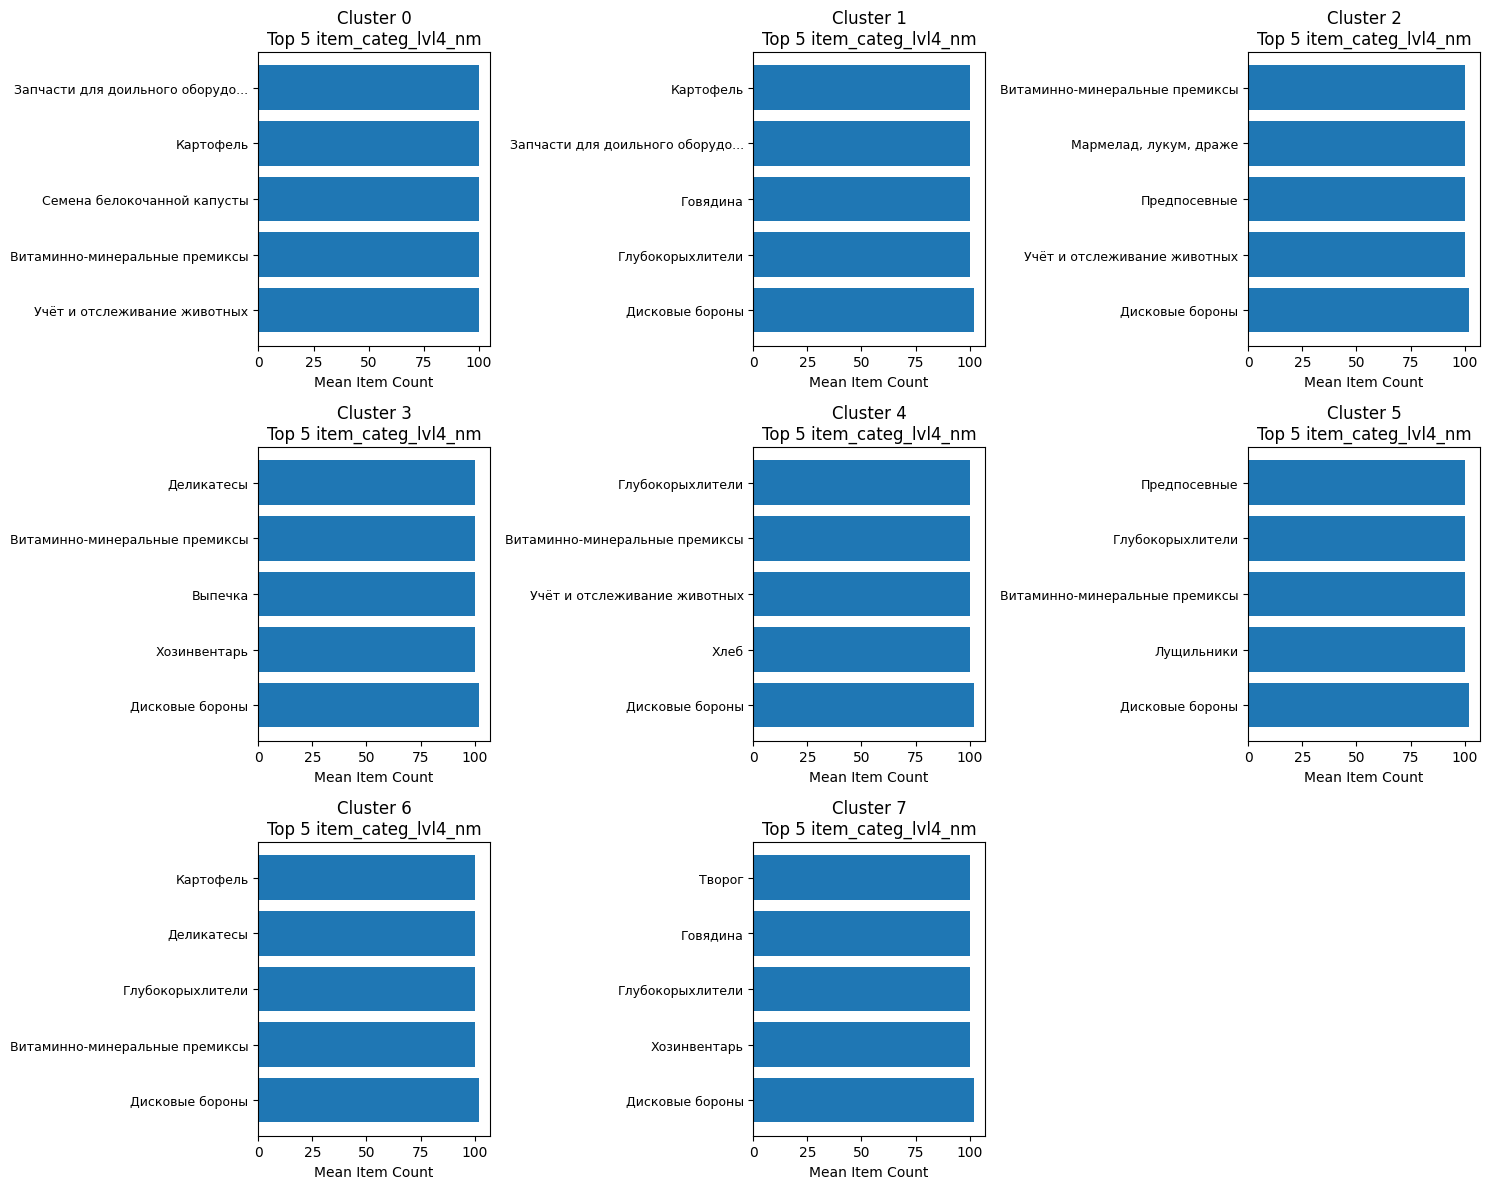

In [ ]:
plot_top_categories_per_cluster_item(clusters_aut_info, 'item_categ_lvl4_nm')

Уровень 5:

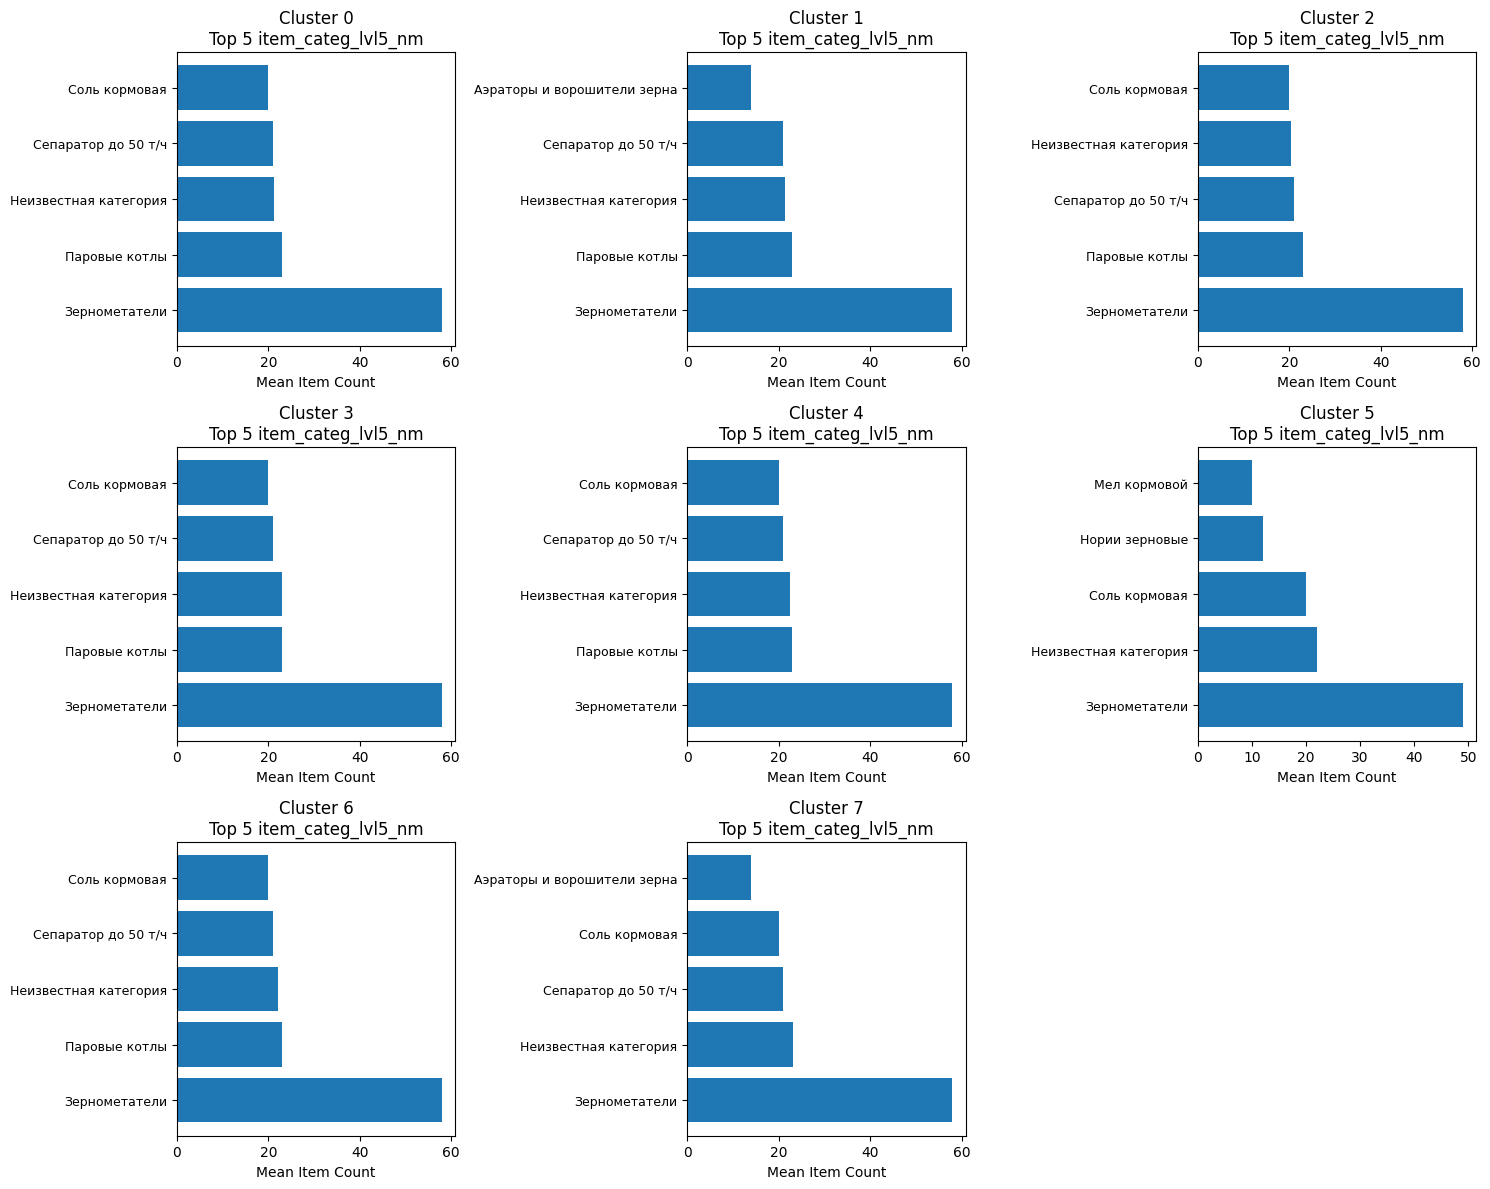

In [ ]:
plot_top_categories_per_cluster_item(clusters_aut_info, 'item_categ_lvl5_nm')

Сделаем анализ по последней непустой категории `last_categ_lvl_nm`. Для этого расширим матрицу `clusters_aut_info`

In [ ]:
clusters_aut_info_latest = wet_info_filled.groupby([
    'cluster',
    'section_category_nm',
    'item_categ_lvl1_nm',
    'item_categ_lvl2_nm',
    'item_categ_lvl3_nm',
    'item_categ_lvl4_nm',
    'item_categ_lvl5_nm',
    'last_categ_lvl_nm'
]).agg(
    count_customer_id=('customer_id', 'nunique'), # здесь мы учли, что пользователей нельзя считать больше одного раза
    count_recomend_item_ids=('recomend_item_ids', 'nunique') # аналогично товары
).reset_index()

clusters_aut_info_latest.head(10)

,cluster,section_category_nm,item_categ_lvl1_nm,item_categ_lvl2_nm,item_categ_lvl3_nm,item_categ_lvl4_nm,item_categ_lvl5_nm,last_categ_lvl_nm,count_customer_id,count_recomend_item_ids
0,0,Каталог,ГСМ,Масла,Гидравлическое масло,Неизвестная категория,Неизвестная категория,Гидравлическое масло,1,41
1,0,Каталог,ГСМ,Масла,Моторное масло,Неизвестная категория,Неизвестная категория,Моторное масло,1,100
2,0,Каталог,ГСМ,Масла,Неизвестная категория,Неизвестная категория,Неизвестная категория,Масла,1,1
3,0,Каталог,ГСМ,Масла,Трансмиссионное масло,Неизвестная категория,Неизвестная категория,Трансмиссионное масло,1,100
4,0,Каталог,ГСМ,Смазочные материалы,Смазки,Неизвестная категория,Неизвестная категория,Смазки,1,100
5,0,Каталог,ГСМ,Технические жидкости,Антифриз,Неизвестная категория,Неизвестная категория,Антифриз,1,100
6,0,Каталог,ГСМ,Технические жидкости,Средства для очистки,Неизвестная категория,Неизвестная категория,Средства для очистки,1,100
7,0,Каталог,ГСМ,Технические жидкости,Тормозная жидкость,Неизвестная категория,Неизвестная категория,Тормозная жидкость,1,17
8,0,Каталог,ГСМ,Технические жидкости,Тосол,Неизвестная категория,Неизвестная категория,Тосол,1,20
9,0,Каталог,ГСМ,Топливо,Бензин,Неизвестная категория,Неизвестная категория,Бензин,1,20


Применяем для пользователей:

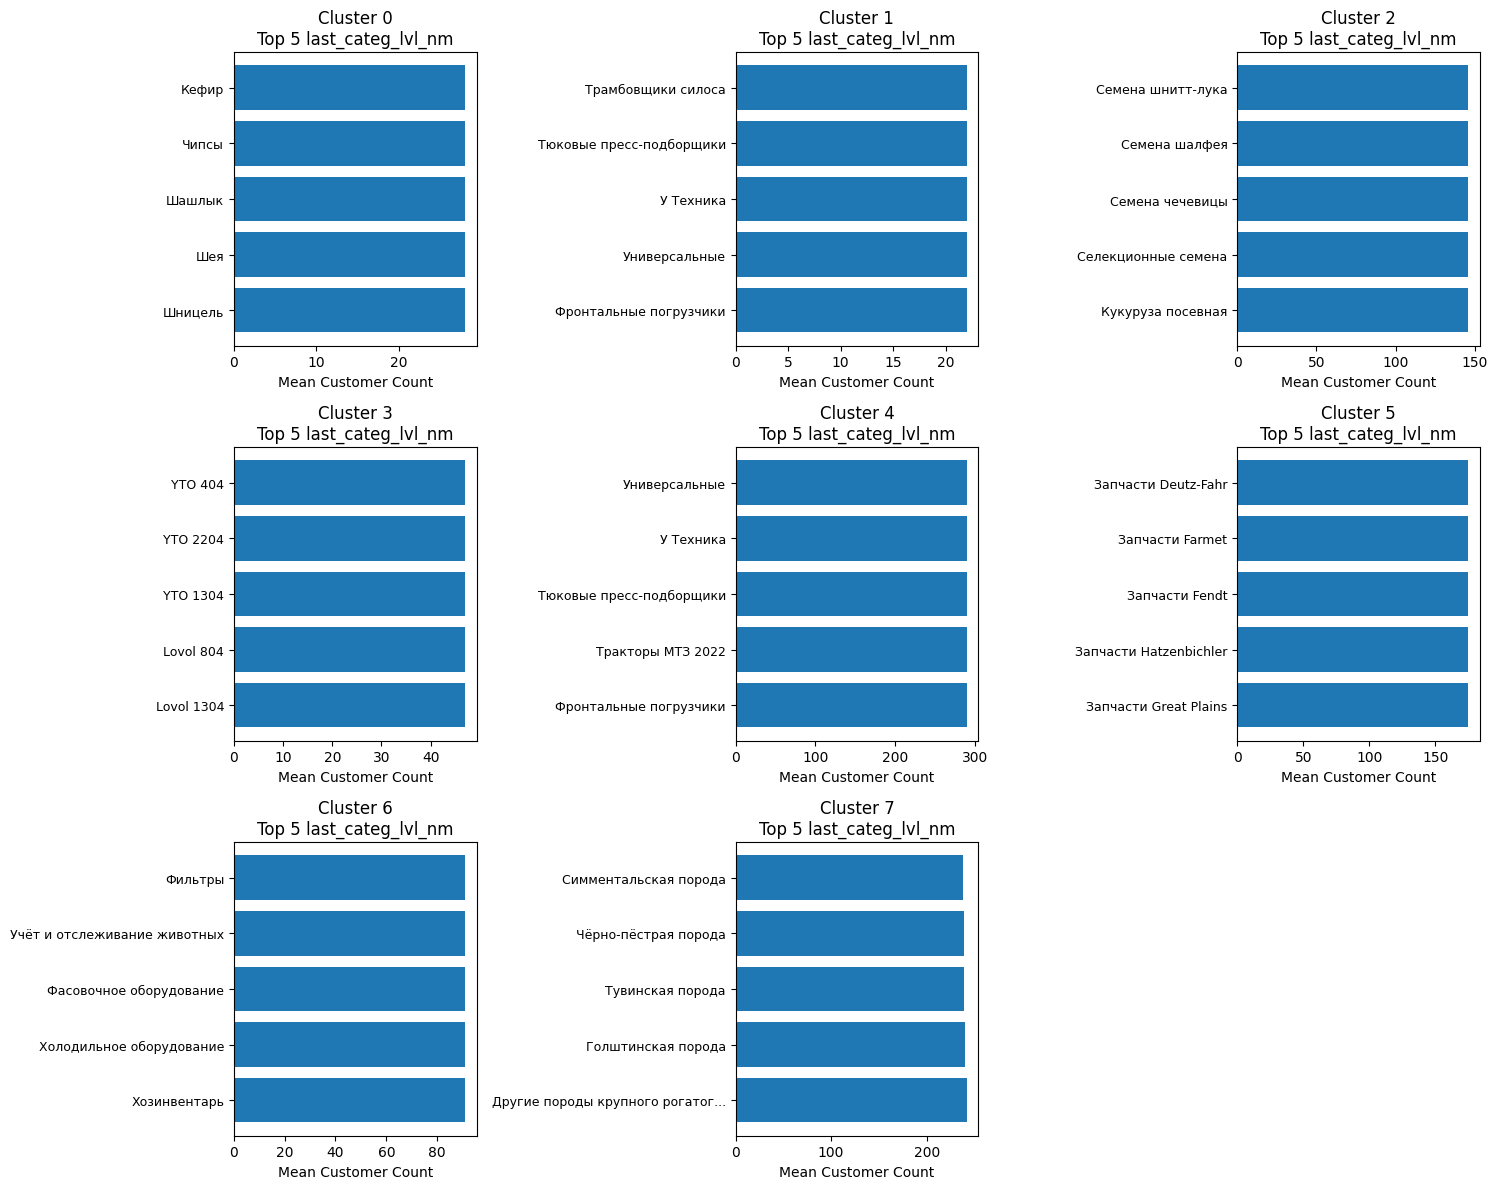

In [ ]:
plot_top_categories_per_cluster_user(clusters_aut_info_latest, 'last_categ_lvl_nm')

Применяем для товаров:

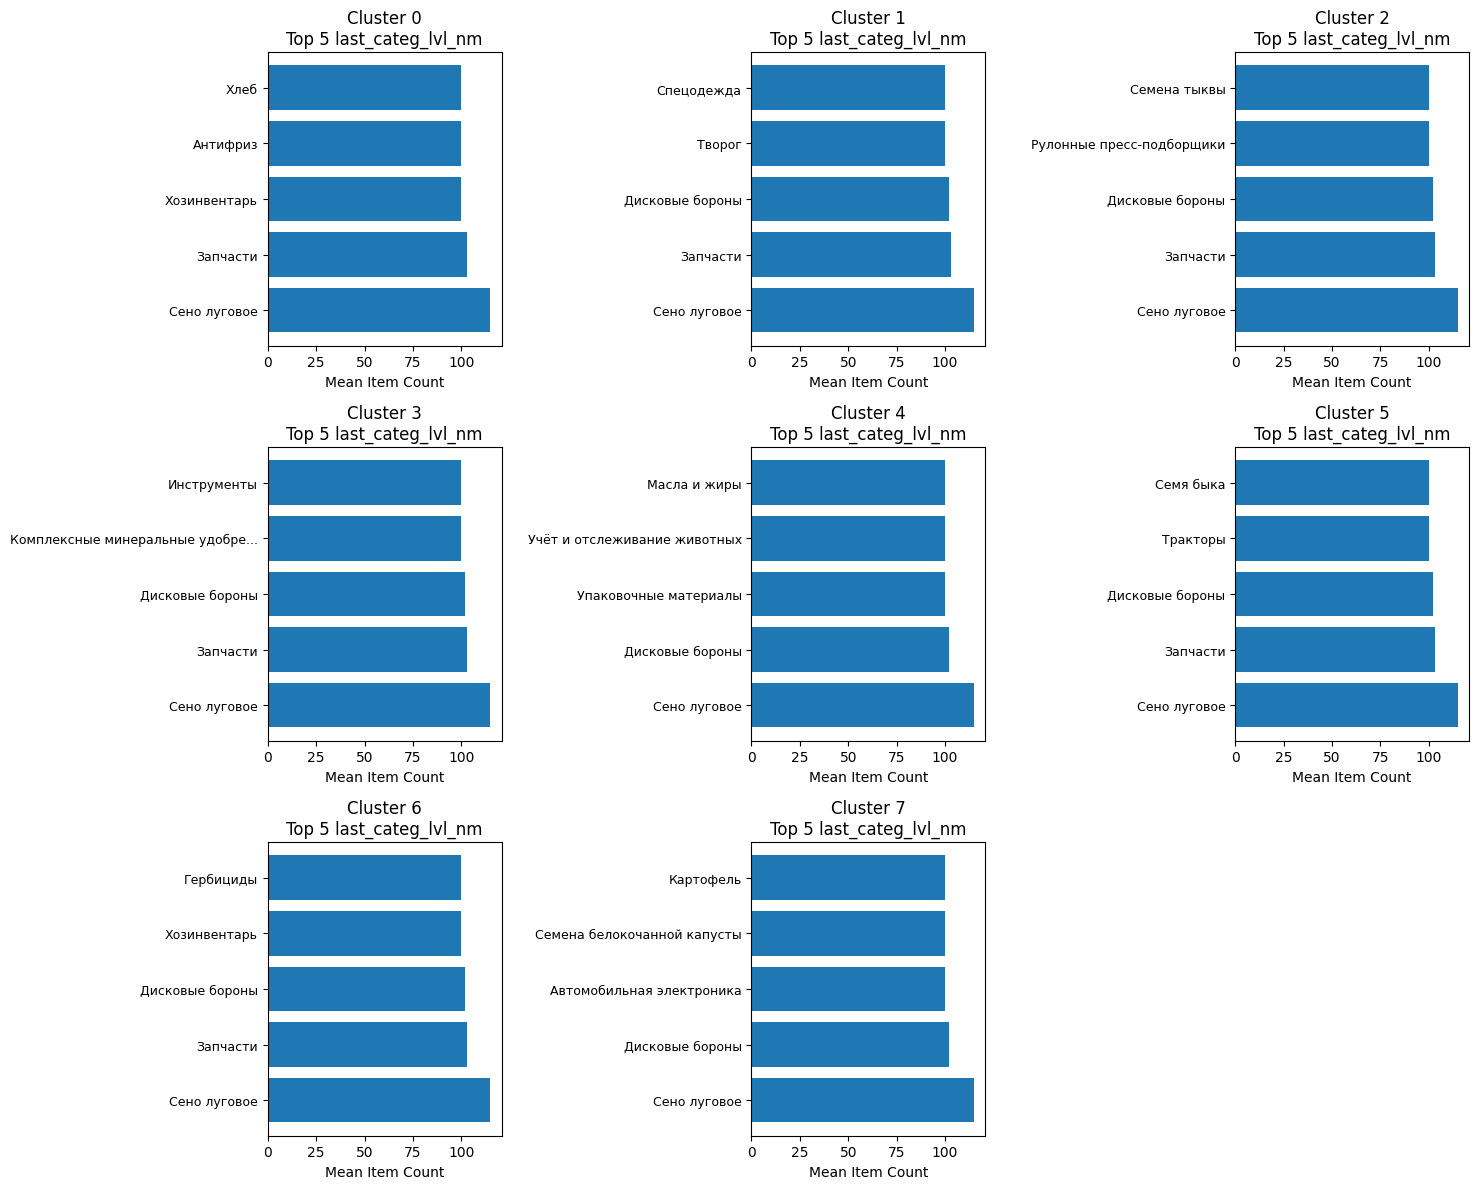

In [ ]:
plot_top_categories_per_cluster_item(clusters_aut_info_latest, 'last_categ_lvl_nm')